# 13 · Khi nào trả "unknown": lượng bằng chứng tối thiểu cho home/office

Classifier v1 (`HeuristicClassifier`, notebook 12) luôn trả một home nếu **có ít nhất 1 phút** của một stay nằm trong khung 22–08 h, và tương tự cho office. Một stay chỉ chạm khung 1 phút vẫn thắng nếu nó là ứng viên duy nhất, và khi đó confidence = 100%. `min_confidence` trong config chưa được dùng ở đâu.

**Câu hỏi:** cần bao nhiêu bằng chứng thì câu trả lời home/office của v1 mới đáng tin, và dưới mức đó thì nên trả "unknown"? Đo bằng chỉ số nào: số đêm có dữ liệu, số phút của stay thắng trong khung, số lần quay lại cùng chỗ, hay confidence?

**Không có nhãn home/office thật**, nên không đo được độ đúng. Notebook này đo **độ ổn định (split-half)**: chia dữ liệu của mỗi user thành hai nửa, chạy đúng luật v1 trên từng nửa, rồi xem hai nửa có chọn cùng một chỗ không (hai stay thắng cách nhau ≤ 200 m, bán kính stay-point của notebook 07). Một câu trả lời không lặp lại được trên một nửa dữ liệu khác thì không thể đúng một cách đáng tin. Điều ngược lại không chắc: hai nửa có thể cùng chọn một chỗ sai.

**Ràng buộc của user:** không bỏ user nào; user chỉ có home hoặc chỉ có office là bình thường. "Unknown" là trạng thái **của từng loại** (home, office), không phải loại user khỏi kết quả.

Chỉ dùng stay-point thật của pipeline (`data/processed/staypoints/`), giờ địa phương theo vị trí (notebook 09).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK = "13_minimum_evidence"
DATA_DIR = Path("../data/raw")
OUT_DIR = Path("outputs") / NOTEBOOK
FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR = (OUT_DIR / d for d in ("figures", "tables", "cache", "maps"))
for d in (FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../src").resolve()))
from gps.models.heuristic import HeuristicClassifier

STAY_DIR = Path("../data/processed/staypoints")
SHARED_PAIRS = Path("outputs/11_shared_recordings/tables/shared_pairs.csv")
NEAR_M = 200                     # "cùng một chỗ" = bán kính stay-point (notebook 07)
EARTH_M = 6_371_008.8
TYPES = {"home": "home_min", "office": "office_min"}
RULE_COLORS = {"v1": "#2a78d6", "area200": "#eb6834", "chance": "#8a8980"}
RULE_NAMES = {"v1": "v1 (per stay)", "area200": "200 m area (v2-like, comparison only)",
              "chance": "chance (random candidate in each half)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
clf = HeuristicClassifier()
rng = np.random.default_rng(13)

## 1. Dữ liệu và kiểm tra rằng notebook tái hiện đúng v1
Với mỗi stay (≥ 30 phút, `min_duration_minutes` của v1), notebook tính:
- `home_min`, `office_min`: số phút trong khung, dùng **chính hàm** `HeuristicClassifier.window_minutes` của `src/`;
- `nights`: các đêm (đêm của ngày *d* = 22 h ngày *d* → 08 h ngày *d*+1) mà stay có ít nhất 1 phút trong khung home;
- `office_days`: các ngày thứ 2–6 mà stay có ít nhất 1 phút trong 09–18 h.

Sau đó notebook chọn stay thắng theo đúng luật v1 (nhiều phút nhất; hoà thì stay dài hơn, rồi đến sớm hơn) và so với `HeuristicClassifier.predict` trên toàn bộ dữ liệu của mỗi user.

**Nhóm user dùng chung file.** Notebook 11 cho thấy 52 user có file `.plt` giống hệt nhau. Các user này không độc lập về mặt thống kê, nên mọi khoảng tin cậy ở đây được bootstrap **theo nhóm** (các user nối với nhau qua file chung là một nhóm), không theo từng user.

In [2]:
paths = sorted(STAY_DIR.glob("user_*.parquet"))
stays = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)
stays["user_id"] = stays["user_id"].astype(str).str.zfill(3)
stays = stays[stays["duration_minutes"] >= clf.min_duration_minutes].reset_index(drop=True)

DAY = pd.Timedelta(days=1)


def window_days(arrival, departure, start, end, weekdays=None):
    """Các ngày d (date) mà [arrival, departure) chạm khung mở lúc start giờ ngày d."""
    out = []
    d = (arrival - DAY).normalize()
    while d <= departure:
        opens = d + pd.Timedelta(hours=start)
        closes = d + pd.Timedelta(hours=end if end > start else end + 24)
        if min(departure, closes) > max(arrival, opens) and (weekdays is None or d.dayofweek in weekdays):
            out.append(d.date())
        d += DAY
    return out


rows = [(*clf.window_minutes(a.to_pydatetime(), d.to_pydatetime()),
         window_days(a, d, clf.home_hour_start, clf.home_hour_end),
         window_days(a, d, clf.office_hour_start, clf.office_hour_end, clf.work_days))
        for a, d in zip(stays["arrival_local"], stays["departure_local"])]
stays["home_min"], stays["office_min"], stays["nights"], stays["office_days"] = map(list, zip(*rows))
DAYS_COL = {"home": "nights", "office": "office_days"}

# nhóm user dùng chung file (notebook 11): union-find trên các cặp
pairs = pd.read_csv(SHARED_PAIRS, dtype=str)
parent = {}


def root(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for a, b in zip(pairs["user_a"], pairs["user_b"]):
    parent[root(a)] = root(b)
GROUP = {u: root(u) for u in stays["user_id"].unique()}
print(f"Users with >= 1 stay: {len(GROUP)}; stays >= 30 min: {len(stays):,}; "
      f"independent groups after joining users that share files: {len(set(GROUP.values()))}")

Users with >= 1 stay: 174; stays >= 30 min: 18,597; independent groups after joining users that share files: 140


In [3]:
def dist_m(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * EARTH_M * np.arcsin(np.sqrt(h))


def near(df):
    la, lo = df["lat"].to_numpy(), df["lon"].to_numpy()
    return dist_m(la[:, None], lo[:, None], la, lo) <= NEAR_M


def pick(df, kind, rule):
    """Stay thắng của một loại trên một tập stay, cùng các chỉ số bằng chứng.

    rule="v1": điểm = số phút trong khung của chính stay (luật của src/).
    rule="area200": điểm = tổng phút trong khung của mọi stay cách nó <= 200 m (chỉ để so sánh, như notebook 12).
    """
    c = df[df[TYPES[kind]] > 0]
    if c.empty:
        return None
    minutes = c[TYPES[kind]].to_numpy()
    N = near(c)
    score = N @ minutes if rule == "area200" else minutes
    i = int(np.lexsort((c["arrival"].astype("int64").to_numpy(), -c["duration_minutes"].to_numpy(), -score))[0])
    return {"lat": c["lat"].iat[i], "lon": c["lon"].iat[i], "win_min": score[i], "conf": score[i] / minutes.sum(),
            "support": int(N[i].sum()), "total_min": minutes.sum(), "n_cand": len(c),
            "days": len(set().union(*c[DAYS_COL[kind]])), "cand": c[["lat", "lon"]]}


mismatch = 0
for u, g in stays.groupby("user_id"):
    res = clf.predict(g[["lat", "lon", "arrival", "departure"]].to_dict("records"))
    for kind, loc in (("home", res.home), ("office", res.office)):
        p = pick(g, kind, "v1")
        same = (loc is None and p is None) or (loc is not None and p is not None and loc.lat == p["lat"]
                                               and loc.lon == p["lon"] and np.isclose(loc.confidence, p["conf"]))
        mismatch += not same
print(f"Users where the notebook's v1 pick differs from HeuristicClassifier.predict: {mismatch} (of {len(GROUP)} x 2 types)")

Users where the notebook's v1 pick differs from HeuristicClassifier.predict: 0 (of 174 x 2 types)


## 2. Thiết kế split-half
Mỗi stay được gán vào một nửa theo **ngày địa phương lúc đến** (stay kéo dài nhiều ngày nằm trọn trong một nửa):
- `alt_day` (chính): ngày chẵn / ngày lẻ. Hai nửa có cùng khoảng thời gian, nên khác biệt giữa chúng chủ yếu là **nhiễu do lấy mẫu**, đúng thứ cần đo.
- `chrono` (kiểm tra độ nhạy): nửa đầu / nửa sau số ngày có dữ liệu. Cách này còn gộp cả **thay đổi thật** (chuyển nhà, đổi chỗ làm), nên độ ổn định thấp hơn là điều dễ hiểu.

Với mỗi user, mỗi loại, mỗi cách chia: hai nửa đều có ứng viên thì so hai stay thắng. Mỗi cặp ghi lại bằng chứng của **nửa yếu hơn** (giá trị nhỏ hơn của hai nửa), vì một cặp chỉ ổn định được khi cả hai nửa đủ dữ liệu.

**Mốc ngẫu nhiên (`chance`).** Nếu ở mỗi nửa chọn bừa một ứng viên (stay có ≥ 1 phút trong khung), thì xác suất hai lựa chọn cách nhau ≤ 200 m là bao nhiêu? Đây là mức mà một luật "không biết gì" cũng đạt được, vì phần lớn ứng viên của một user tập trung ở vài chỗ. Một chỉ số bằng chứng có ích khi độ ổn định **tách khỏi** mốc này.

Các chỉ số bằng chứng (đo trên nửa yếu hơn):
- `days`: số đêm (home) hoặc số ngày làm việc (office) có ít nhất 1 phút trong khung;
- `total_min`: tổng số phút trong khung của mọi ứng viên;
- `win_min`: số phút trong khung của stay thắng;
- `support`: số ứng viên (kể cả stay thắng) cách stay thắng ≤ 200 m, tức là **số lần user có mặt trong khung ở cùng chỗ đó**;
- `conf`: confidence của v1.

In [4]:
def split_masks(g):
    dates = g["arrival_local"].dt.date
    uniq = np.array(sorted(dates.unique()))
    if len(uniq) < 2:
        return {}
    return {"alt_day": (dates.map(lambda x: x.toordinal()) % 2 == 0).to_numpy(),
            "chrono": (dates < uniq[len(uniq) // 2]).to_numpy()}


rows = []
for u, g in stays.groupby("user_id"):
    for split, m in split_masks(g).items():
        for kind in TYPES:
            for rule in ("v1", "area200"):
                a, b = pick(g[m], kind, rule), pick(g[~m], kind, rule)
                r = {"user_id": u, "group": GROUP[u], "split": split, "type": kind, "rule": rule,
                     "found_halves": (a is not None) + (b is not None)}
                if a is not None and b is not None:
                    ca, cb = a.pop("cand"), b.pop("cand")
                    r["same"] = dist_m(a["lat"], a["lon"], b["lat"], b["lon"]) <= NEAR_M
                    r["chance"] = (dist_m(ca["lat"].to_numpy()[:, None], ca["lon"].to_numpy()[:, None],
                                          cb["lat"].to_numpy(), cb["lon"].to_numpy()) <= NEAR_M).mean()
                    r.update({k: min(a[k], b[k]) for k in ("days", "total_min", "win_min", "support", "conf")})
                rows.append(r)
halves = pd.DataFrame(rows)
pairs_ok = halves[halves["found_halves"] == 2].copy()
pairs_ok["same"] = pairs_ok["same"].astype(bool)


def boot(d, col="same", n=2000):
    """Trung bình và CI 95%, bootstrap theo nhóm user dùng chung file."""
    gs = d.groupby("group")[col].agg(["sum", "size"])
    s, k = gs["sum"].to_numpy(float), gs["size"].to_numpy(float)
    idx = rng.integers(0, len(gs), (n, len(gs)))
    b = s[idx].sum(1) / k[idx].sum(1)
    return pd.Series({"pairs": int(k.sum()), "stable": s.sum() / k.sum(),
                      "ci_lo": np.quantile(b, 0.025), "ci_hi": np.quantile(b, 0.975)})


overall = (pairs_ok.groupby(["split", "type", "rule"])
           .apply(lambda d: pd.concat([boot(d), pd.Series({"chance": d["chance"].mean()})]))
           .reset_index())
found = halves[halves["rule"] == "v1"].groupby(["split", "type"])["found_halves"].value_counts().unstack(fill_value=0)
found.columns = [f"halves_with_answer_{c}" for c in found.columns]
overall.round(3).to_csv(TABLE_DIR / "split_half_overall.csv", index=False)
found.to_csv(TABLE_DIR / "split_half_found.csv")
display(found)
overall.round(3)

halves_with_answer_0  halves_with_answer_1  \
split   type                                                 
alt_day home                      10                    21   
        office                    12                    27   
chrono  home                      10                    22   
        office                    12                    26   

                halves_with_answer_2  
split   type                          
alt_day home                     138  
        office                   130  
chrono  home                     137  
        office                   131

,split,type,rule,pairs,stable,ci_lo,ci_hi,chance
0,alt_day,home,area200,138.0,0.630,0.549,0.711,0.272
1,alt_day,home,v1,138.0,0.406,0.320,0.500,0.272
2,alt_day,office,area200,130.0,0.631,0.534,0.716,0.226
3,alt_day,office,v1,130.0,0.415,0.331,0.504,0.226
4,chrono,home,area200,137.0,0.467,0.387,0.544,0.264
5,chrono,home,v1,137.0,0.372,0.294,0.459,0.264
6,chrono,office,area200,131.0,0.496,0.410,0.583,0.219
7,chrono,office,v1,131.0,0.351,0.270,0.431,0.219


## 3. Có nhiều dữ liệu hơn thì v1 ổn định hơn không?
Nếu v1 sai chủ yếu vì thiếu dữ liệu, thì độ ổn định phải **tăng** theo số đêm / số ngày làm việc và theo tổng số phút trong khung. Hình so v1 với chấm điểm theo vùng 200 m (chỉ để so sánh, giống notebook 12) và với mốc ngẫu nhiên. Thanh dọc là CI 95% (bootstrap theo nhóm).

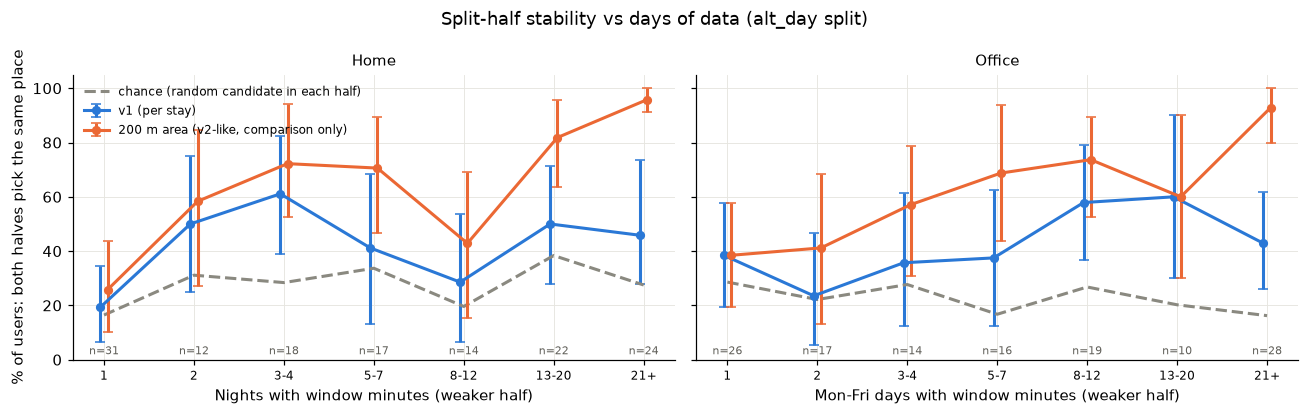

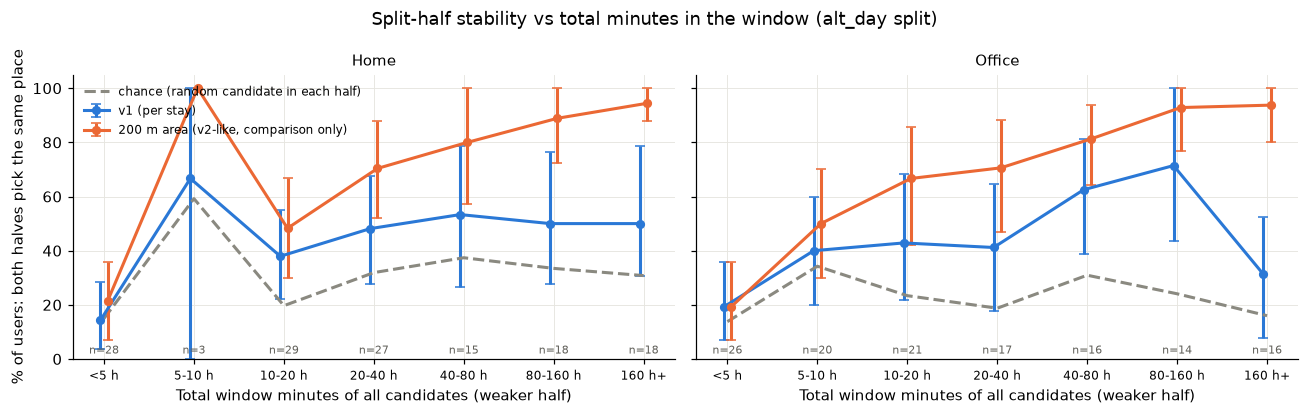

In [5]:
def curve(d, col, bins, labels):
    d = d.assign(bin=pd.cut(d[col], bins, right=False, labels=labels))
    out = d.groupby(["type", "rule", "bin"], observed=True).apply(
        lambda x: pd.concat([boot(x), pd.Series({"chance": x["chance"].mean()})]))
    return out.reset_index()


def plot_curves(tab, col_label, title, fname, rules=("v1", "area200")):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, kind in zip(axes, TYPES):
        t = tab[tab["type"] == kind]
        x_labels = list(t["bin"].cat.categories) if hasattr(t["bin"], "cat") else list(dict.fromkeys(t["bin"]))
        for k, rule in enumerate(rules):
            r = t[t["rule"] == rule].set_index("bin").reindex(x_labels)
            x = np.arange(len(x_labels)) + (k - (len(rules) - 1) / 2) * 0.08
            ax.errorbar(x, r["stable"] * 100, yerr=[(r["stable"] - r["ci_lo"]) * 100, (r["ci_hi"] - r["stable"]) * 100],
                        color=RULE_COLORS[rule], linewidth=2, marker="o", markersize=5, capsize=3, label=RULE_NAMES[rule])
            if k == 0:
                ax.plot(np.arange(len(x_labels)), r["chance"] * 100, color=RULE_COLORS["chance"], linewidth=2,
                        linestyle="--", label=RULE_NAMES["chance"])
                for i, n in enumerate(r["pairs"]):
                    if pd.notna(n):
                        ax.annotate(f"n={int(n)}", (i, 2), ha="center", fontsize=7, color="#5f5e58")
        ax.set_xticks(range(len(x_labels)), x_labels, fontsize=8)
        ax.set_ylim(0, 105)
        ax.set_xlabel(col_label[kind])
        ax.set_title(kind.capitalize(), fontsize=10)
    axes[0].set_ylabel("% of users: both halves pick the same place")
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname)
    plt.show()


main = pairs_ok[pairs_ok["split"] == "alt_day"]
DAY_BINS, DAY_LABELS = [1, 2, 3, 5, 8, 13, 21, 10_000], ["1", "2", "3-4", "5-7", "8-12", "13-20", "21+"]
by_days = curve(main, "days", DAY_BINS, DAY_LABELS)
by_days.round(3).to_csv(TABLE_DIR / "stability_by_days.csv", index=False)
plot_curves(by_days, {"home": "Nights with window minutes (weaker half)", "office": "Mon-Fri days with window minutes (weaker half)"},
            "Split-half stability vs days of data (alt_day split)", "fig01_stability_by_days.png")

TOT_BINS = [0, 300, 600, 1200, 2400, 4800, 9600, 1e9]
TOT_LABELS = ["<5 h", "5-10 h", "10-20 h", "20-40 h", "40-80 h", "80-160 h", "160 h+"]
by_total = curve(main, "total_min", TOT_BINS, TOT_LABELS)
by_total.round(3).to_csv(TABLE_DIR / "stability_by_total_window_minutes.csv", index=False)
plot_curves(by_total, {k: "Total window minutes of all candidates (weaker half)" for k in TYPES},
            "Split-half stability vs total minutes in the window (alt_day split)", "fig02_stability_by_total_minutes.png")

## 4. Chỉ số nào báo trước một câu trả lời v1 không đáng tin?
Mục 3 cho thấy lượng dữ liệu tổng không cứu được v1. Phần này xét các chỉ số **của chính stay thắng**, những thứ classifier có sẵn lúc trả lời:
- `win_min`: stay thắng có bao nhiêu phút trong khung. Khung home dài 10 h (600 phút/đêm), khung office 9 h (540 phút/ngày).
- `support`: stay thắng có phải là chỗ user **quay lại nhiều lần** trong khung không.
- `conf`: confidence của v1 (`win_min` / tổng phút của mọi ứng viên).

Cả hai cách chia (`alt_day`, `chrono`) đều được vẽ cho v1.

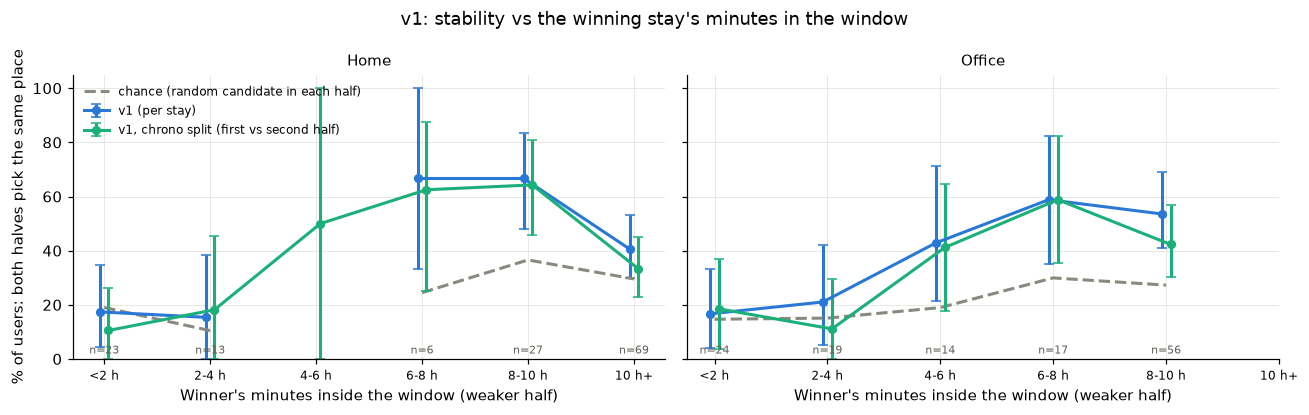

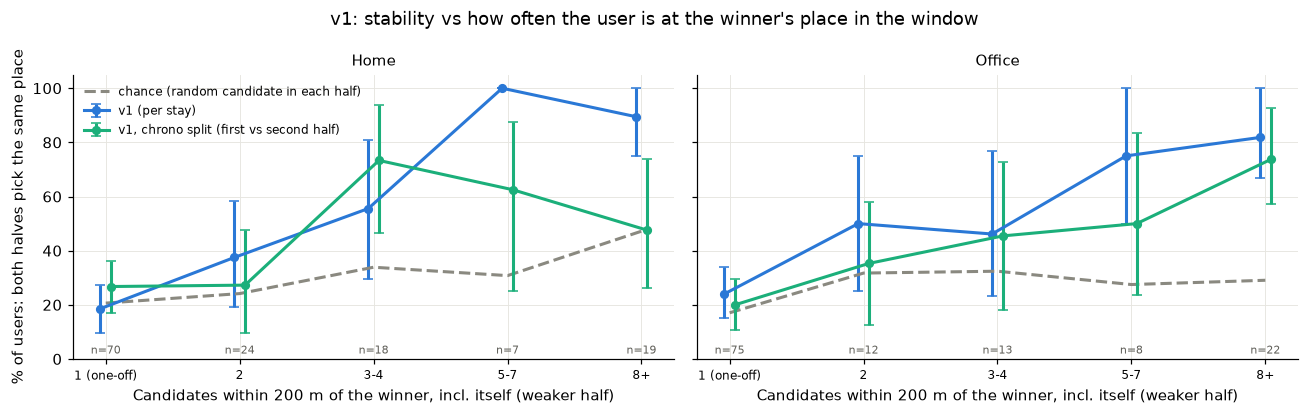

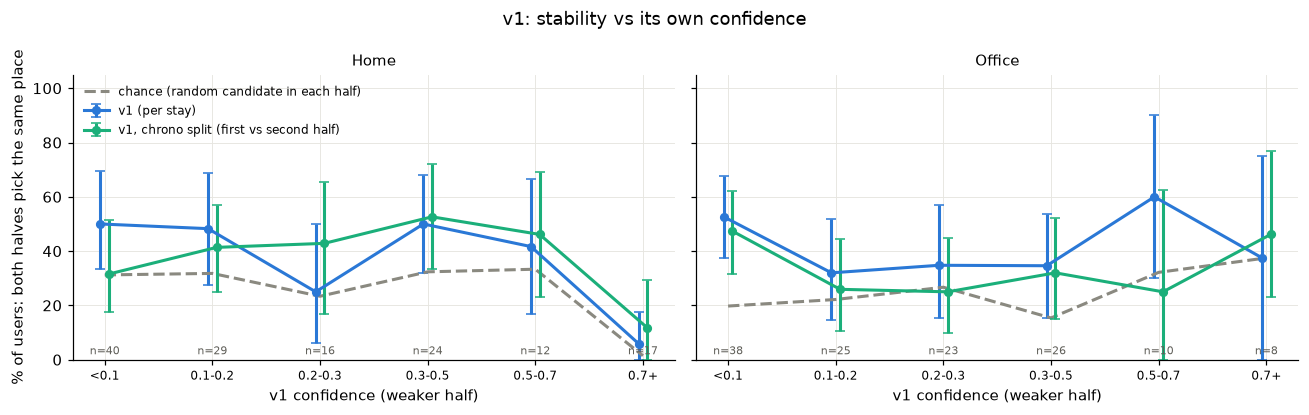

In [6]:
v1 = pairs_ok[pairs_ok["rule"] == "v1"]


def curve_by_split(d, col, bins, labels):
    tabs = []
    for split, x in d.groupby("split"):
        t = curve(x, col, bins, labels)
        t["rule"] = "v1" if split == "alt_day" else "v1_chrono"
        tabs.append(t)
    return pd.concat(tabs, ignore_index=True)


RULE_COLORS["v1_chrono"], RULE_NAMES["v1_chrono"] = "#1baf7a", "v1, chrono split (first vs second half)"
WIN_BINS, WIN_LABELS = [0, 120, 240, 360, 480, 600, 1e9], ["<2 h", "2-4 h", "4-6 h", "6-8 h", "8-10 h", "10 h+"]
by_win = curve_by_split(v1, "win_min", WIN_BINS, WIN_LABELS)
by_win.round(3).to_csv(TABLE_DIR / "v1_stability_by_winner_minutes.csv", index=False)
plot_curves(by_win, {k: "Winner's minutes inside the window (weaker half)" for k in TYPES},
            "v1: stability vs the winning stay's minutes in the window", "fig03_v1_stability_by_winner_minutes.png",
            rules=("v1", "v1_chrono"))

SUP_BINS, SUP_LABELS = [1, 2, 3, 5, 8, 10_000], ["1 (one-off)", "2", "3-4", "5-7", "8+"]
by_sup = curve_by_split(v1, "support", SUP_BINS, SUP_LABELS)
by_sup.round(3).to_csv(TABLE_DIR / "v1_stability_by_support.csv", index=False)
plot_curves(by_sup, {k: "Candidates within 200 m of the winner, incl. itself (weaker half)" for k in TYPES},
            "v1: stability vs how often the user is at the winner's place in the window",
            "fig04_v1_stability_by_support.png", rules=("v1", "v1_chrono"))

CONF_BINS, CONF_LABELS = [0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.01], ["<0.1", "0.1-0.2", "0.2-0.3", "0.3-0.5", "0.5-0.7", "0.7+"]
by_conf = curve_by_split(v1, "conf", CONF_BINS, CONF_LABELS)
by_conf.round(3).to_csv(TABLE_DIR / "v1_stability_by_confidence.csv", index=False)
plot_curves(by_conf, {k: "v1 confidence (weaker half)" for k in TYPES},
            "v1: stability vs its own confidence", "fig05_v1_stability_by_confidence.png", rules=("v1", "v1_chrono"))

### 4.1 Vì sao home ≥ 10 h lại kém ổn định hơn 8–10 h?
Khung home dài đúng 600 phút, nên một stay phủ trọn một đêm có đúng 600 phút; chỉ stay kéo dài qua nhiều đêm mới vượt 600. Khung office dài 540 phút một ngày. Bảng dưới chia stay thắng trên **toàn bộ dữ liệu** của mỗi user thành ba loại (chưa trọn khung / đúng trọn một khung / hơn một khung) và đếm:
- `median_tied_at_top`: số ứng viên có **cùng số phút cao nhất** với stay thắng. Khi > 1, v1 phải chọn bằng luật phá hoà (stay dài hơn, rồi đến sớm hơn), không phải bằng bằng chứng;
- `share_one_off`: tỉ lệ stay thắng có `support` = 1;
- `share_same_as_area200`: tỉ lệ stay thắng nằm trong 200 m của nơi thắng khi chấm theo vùng 200 m.

In [7]:
FULL_WINDOW = {"home": (clf.home_hour_end - clf.home_hour_start) % 24 * 60,
               "office": (clf.office_hour_end - clf.office_hour_start) * 60}
full = []
for u, g in stays.groupby("user_id"):
    for kind in TYPES:
        p = pick(g, kind, "v1")
        if p is None:
            full.append({"user_id": u, "type": kind, "found": False})
            continue
        q = pick(g, kind, "area200")
        p.pop("cand"), q.pop("cand")
        minutes = g.loc[g[TYPES[kind]] > 0, TYPES[kind]].to_numpy()
        full.append({"user_id": u, "type": kind, "found": True, **p,
                     "tied_at_top": int((minutes >= p["win_min"] - 1e-9).sum()), "area_support": q["support"],
                     "area_same_place": bool(dist_m(p["lat"], p["lon"], q["lat"], q["lon"]) <= NEAR_M)})
full = pd.DataFrame(full)
f = full[full["found"].astype(bool)].copy()
f["winner_fills"] = np.select(
    [f["win_min"] < f["type"].map(FULL_WINDOW) - 1e-9, f["win_min"] <= f["type"].map(FULL_WINDOW) + 1e-9],
    ["less than one full window", "exactly one full window"], "more than one window")
fills = (f.groupby(["type", "winner_fills"])
         .agg(users=("user_id", "size"), median_tied_at_top=("tied_at_top", "median"),
              share_tied=("tied_at_top", lambda s: (s > 1).mean()),
              share_one_off=("support", lambda s: (s == 1).mean()),
              share_same_as_area200=("area_same_place", "mean")))
fills.round(3).to_csv(TABLE_DIR / "v1_winner_fills_window.csv")
fills.round(3)

users  median_tied_at_top  share_tied  \
type   winner_fills                                                       
home   exactly one full window       94                 3.0       0.798   
       less than one full window     63                 1.0       0.016   
       more than one window           7                 1.0       0.000   
office exactly one full window       52                 2.0       0.654   
       less than one full window    101                 1.0       0.000   
       more than one window           6                 1.0       0.000   

                                  share_one_off share_same_as_area200  
type   winner_fills                                                    
home   exactly one full window            0.223              0.744681  
       less than one full window          0.460              0.936508  
       more than one window               0.143              0.142857  
office exactly one full window            0.154              0.634615  
       less than one full window          0.436              0.841584  
       more than one window               0.167              0.666667

## 5. Trên toàn bộ dữ liệu: mỗi luật "unknown" ứng viên ảnh hưởng bao nhiêu user?
Các ngưỡng ứng viên lấy từ mục 4, ở chỗ đường v1 **bắt đầu tách khỏi** mốc ngẫu nhiên. Ngưỡng được áp lên bằng chứng của **toàn bộ dữ liệu** mà classifier nhận (ở mục 4 là của một nửa: đường cong trả lời "với bằng chứng mức này thì câu trả lời có lặp lại được không").

Cột `area200_support_3plus` đếm những user bị luật đó chuyển thành unknown nhưng có một vùng 200 m với ≥ 3 lần có mặt trong khung, tức là v2 nhiều khả năng sẽ trả lời được. Đây là cái giá của việc v1 chỉ xét từng stay.

In [8]:
def gate_table(full):
    rows = []
    for kind, d in full.groupby("type"):
        f = d[d["found"].astype(bool)]
        gates = {"no candidate (current behaviour)": pd.Series(False, index=f.index),
                 "winner < 240 window minutes": f["win_min"] < 240,
                 "winner is a one-off (support 1)": f["support"] < 2,
                 "either of the two": (f["win_min"] < 240) | (f["support"] < 2)}
        for name, unknown in gates.items():
            rows.append({"type": kind, "unknown_rule": name, "users": len(d),
                         "answered": int((~unknown).sum()), "unknown": int(len(d) - (~unknown).sum()),
                         "area200_support_3plus": int((unknown & (f["area_support"] >= 3)).sum())})
    return pd.DataFrame(rows)


gates = gate_table(full)
gates.to_csv(TABLE_DIR / "unknown_rule_impact.csv", index=False)
n_days = stays.groupby("user_id")["arrival_local"].apply(lambda s: s.dt.date.nunique())
print(f"Users with stays on < 5 days: {(n_days < 5).sum()} of {len(n_days)}; "
      f"users with no stay at all (not in this table, always unknown): {len(paths) - len(n_days)}")
gates

Users with stays on < 5 days: 42 of 174; users with no stay at all (not in this table, always unknown): 8


,type,unknown_rule,users,answered,unknown,area200_support_3plus
0,home,no candidate (current behaviour),174,164,10,0
1,home,winner < 240 window minutes,174,132,42,5
2,home,winner is a one-off (support 1),174,113,61,7
3,home,either of the two,174,104,70,11
4,office,no candidate (current behaviour),174,159,15,0
5,office,winner < 240 window minutes,174,126,48,6
6,office,winner is a one-off (support 1),174,106,68,13
7,office,either of the two,174,100,74,17


## 6. Kết luận

**Đã kiểm chứng trên dữ liệu** (174 user có stay, 18.597 stay; 140 nhóm độc lập sau khi gộp các user dùng chung file; split chính `alt_day`, kiểm tra lại bằng `chrono`):

1. **Notebook tái hiện đúng v1.** Stay thắng và confidence trùng với `HeuristicClassifier.predict` ở cả 174 × 2 trường hợp.
2. **v1 chỉ ổn định hơn đoán ngẫu nhiên một chút** (bảng `split_half_overall.csv`):
   - home: 40,6% (CI 32–50%) so với mốc ngẫu nhiên 27,2%;
   - office: 41,5% (CI 33–50%) so với 22,6%;
   - chấm theo vùng 200 m (chỉ để so sánh): 63% / 63%.
   - Chia `chrono` (có cả chuyển nhà thật) cho thấp hơn ở mọi luật: v1 37% / 35%, vùng 200 m 47% / 50%.
3. **Thêm dữ liệu không làm v1 ổn định hơn** (Hình 1, 2). Theo tổng số phút trong khung của nửa yếu hơn:
   - vùng 200 m tăng đều từ khoảng 20% (< 5 h) lên **94%** (160 h trở lên) ở cả home và office;
   - v1 từ 10 h trở lên dao động 38–71% mà không có xu hướng tăng, và ở 160 h trở lên chỉ còn 50% (home) / 31% (office). Theo số đêm / số ngày (Hình 1) cũng vậy: vùng 200 m lên 96% / 93% ở 21 đêm trở lên, v1 46% / 43%.
   - Vì vậy **một ngưỡng "tối thiểu N đêm / N ngày" không sửa được v1.** Giới hạn nằm ở luật xét từng stay, không phải ở lượng dữ liệu.
4. **Nguyên nhân: hoà ở mức trọn khung** (mục 4.1). 94/164 user có stay thắng home phủ đúng một đêm trọn (600 phút); 80% trong số đó hoà với các đêm trọn khác (trung vị 3 ứng viên). Office: 52 user, 65% hoà. Khi đó luật phá hoà chọn, không phải bằng chứng. Stay thắng dài hơn một khung rất hiếm (7 home, 6 office).
5. **Hai dấu hiệu cho thấy câu trả lời v1 không hơn đoán ngẫu nhiên** (Hình 3, 4; cả hai cách chia đều cho cùng kết quả):
   - **stay thắng có < 4 h trong khung**: home 17% / 15% (< 2 h / 2–4 h) so với mốc 19% / 11%; office 17% / 21% so với 15% / 15%. Từ 4 h trở lên, v1 tách khỏi mốc: office 43–59%, home 67% (6–10 h). Ranh giới nằm giữa hai ô 2–4 h và 4–6 h; home gần như không có cặp nào ở 4–6 h, nên 240 phút là **mép ô, không phải điểm tối ưu**.
   - **stay thắng là chỗ "một lần"** (`support` = 1, không có ứng viên nào khác trong 200 m): home 19% so với mốc 21%, office 24% so với 17%, mỗi ô có 70–75 cặp nên CI hẹp (10–34%). `support` = 2 chưa kết luận được (CI 19–58% / 25–75%, `chrono` ngang mốc). Từ 5 trở lên: 75–100%.
6. **Confidence của v1 không báo được độ tin cậy** (Hình 5). Độ ổn định không tăng theo confidence; ô cao nhất (≥ 0,7) lại thấp nhất ở home: 6% (`chrono` 12%). Confidence cao nghĩa là một stay chiếm gần hết phút trong khung, thường vì user có rất ít ứng viên. Vì vậy **không dùng `min_confidence` làm ngưỡng unknown cho v1.**
7. **Ảnh hưởng trên toàn bộ dữ liệu** (bảng `unknown_rule_impact.csv`, trên 174 user có stay; 8 user không có stay nào luôn là unknown):

   | Luật unknown | Home trả lời | Office trả lời | Trong số unknown, có vùng 200 m ≥ 3 lần (v2 có thể trả lời) |
   |---|---|---|---|
   | chỉ khi không có ứng viên (hiện tại) | 164 | 159 | 0 / 0 |
   | stay thắng < 240 phút trong khung | 132 | 126 | 5 / 6 |
   | stay thắng là chỗ một lần | 113 | 106 | 7 / 13 |
   | một trong hai | 104 | 100 | 11 / 17 |

   Phần lớn user bị chuyển thành unknown **không có chỗ nào lặp lại** trong khung, nên cả v2 cũng khó trả lời cho họ.

**Đề xuất cho `src/` (chờ duyệt):**
- Mỗi loại (home, office) có `status`: `found` hoặc `unknown`, kèm lý do (`no_candidate`, `too_few_window_minutes`, `one_off_place`). Không bỏ user nào; chỉ có home hoặc chỉ có office là kết quả hợp lệ.
- Unknown khi stay thắng có **< 240 phút** trong khung, **hoặc** là chỗ **một lần** (không có stay nào khác có phút trong khung trong vòng 200 m). Luật thứ hai chỉ **đếm** stay gần, không gộp và không đổi stay thắng, nên v1 vẫn xét từng stay như spec.
- Trả về các chỉ số bằng chứng (`window_minutes`, `support`) để phía dùng tự đánh giá; ghi rõ trong docs rằng confidence của v1 **không** phải độ tin cậy.
- Bỏ `min_confidence` (không dùng, và mục 6 cho thấy nó không có ý nghĩa với v1); việc dọn config làm ở task 3.4.
- Ngưỡng cho v2 (task 3.5) nên đo lại trên vùng: ở đó lượng dữ liệu **có** ích (Hình 2).

**Chưa kiểm chứng / giới hạn:**
- Độ ổn định là **tính nhất quán, không phải độ đúng**: hai nửa có thể cùng chọn sai một chỗ. Không có nhãn home/office thật.
- Ngưỡng được đo trên **một nửa** dữ liệu rồi áp cho toàn bộ dữ liệu mà classifier nhận. Đường cong trả lời "với bằng chứng ở mức này, câu trả lời có lặp lại được không", nên áp lên chính bằng chứng của input là hợp lý; nhưng user nhiều dữ liệu có `support` toàn phần cao hơn nửa của họ.
- Các ô có 6–30 cặp, CI rộng; chỉ hai kết luận có CI hẹp: "< 4 h" và "một lần" ngang mốc ngẫu nhiên.
- `support` = 2 chưa đủ dữ liệu để quyết; đề xuất dùng ngưỡng thấp nhất (≥ 2) để không chuyển user thành unknown khi chưa có bằng chứng.